In [2]:
# Import the libraries
import re
import urllib.request
from importlib.metadata import version
import tiktoken
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from matplotlib import pyplot as plt

### Implementing GPT from Scratch - GPT architecture
- Generative Pretrained transformers (GPT)
- Parameters refers to weights that are optimized during the training process
- GPT2- 1.5 B parameters and GPT3-175 B parameters

 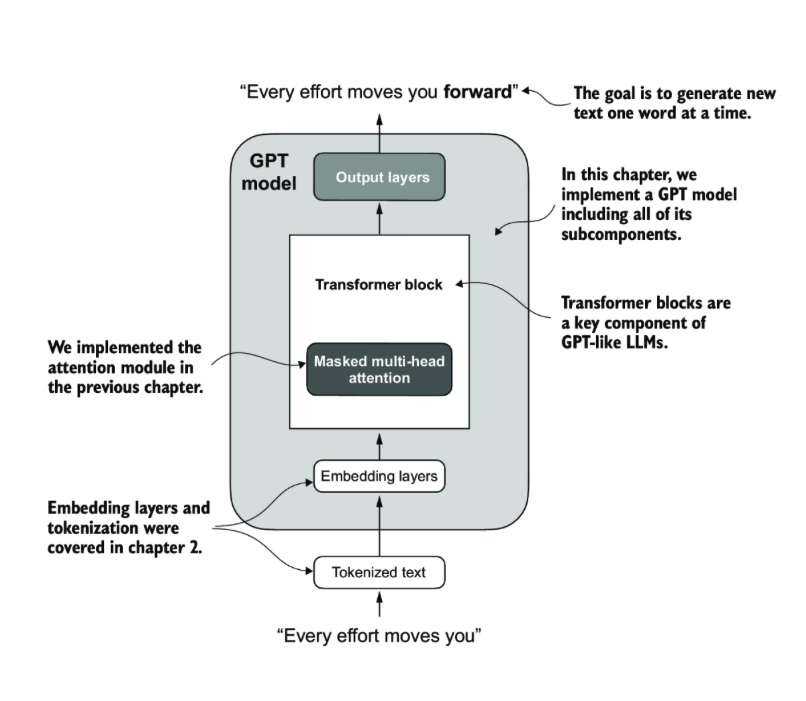

In [3]:
# We will try to develop the model of the smallest GPT2 version
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size - by BPE tokenizer
    "context_length": 1024,  # Context length - maximum length of the input tokens
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers - Number of transformer blocks
    "drop_rate": 0.1,        # Dropout rate - 10 % random drop out of hidden units
    "qkv_bias": False        # Query-Key-Value bias- turning off bias parameter
}

In [4]:
# A dummy place holder GPT model architecture

import torch
import torch.nn as nn

class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(               #1 Creating a sequence of transformer blocks
            *[DummyTransformerBlock(cfg)               #1
              for _ in range(cfg["n_layers"])]         #1
        )                                              #1
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])     #2 Layer normalization block
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

class DummyTransformerBlock(nn.Module):    #3
    def __init__(self, cfg):
        super().__init__()

    def forward(self, x):     #4
        return x

class DummyLayerNorm(nn.Module):           #5
    def __init__(self, normalized_shape, eps=1e-5):    #6
        super().__init__()

    def forward(self, x):
        return x

#### Layer Normalizations
- While training deep neural networks, sometimes can lead to vanishing or exploding gradients
- This affects the weight update process or basically the learning process which minimizes the loss function >> unstable training
- Difficulty learning the underlying pattern in the data for accurate predictions.
- Layer normalizations: standardize / normalize the outputs of neural network within a layer to mean zero and unit variance
- Reduces the internal covariate shift
- This improves the stability, efficiency of training process and faster convergence to effective weights.
- Usually applied before and after the network.
- This is usually different from batch normalizations which normalizes across the batch dimension and it needs more memory resources.
- Layer normalization is more beneficial for distributed training with constrained resources.

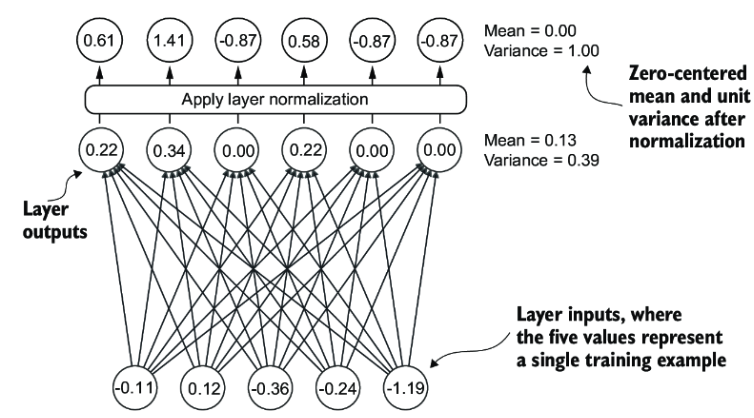

In [5]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5 # To avoid division by zero
        self.scale = nn.Parameter(torch.ones(emb_dim)) # Trainable parameters
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False) # Using n instead of n-1 for sample variance as it won't matter when n>>1
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift # LLM would adjust these during training if it finds that doing so would improve model performance

In [19]:
torch.manual_seed(123)
batch_example = torch.randn(2, 5, 12)

ln = LayerNorm(emb_dim=12)
out_ln = ln(batch_example)
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean_bf:", batch_example.mean(dim=-1))
print("Var_bf:", batch_example.var(dim=-1))

print("Mean:\n", mean)
print("Variance:\n", var) 
print(batch_example.shape,  mean.shape)

Mean_bf: tensor([[-0.1215,  0.5372, -0.6492, -0.0281,  0.4477],
        [-0.0444,  0.0695, -0.5353, -0.4614,  0.1693]])
Var_bf: tensor([[0.5128, 0.7505, 1.5704, 0.5900, 1.3795],
        [1.1675, 0.5603, 0.7502, 1.2507, 2.6777]])
Mean:
 tensor([[[ 1.9868e-08],
         [-4.4703e-08],
         [ 1.9868e-08],
         [-1.9868e-08],
         [ 0.0000e+00]],

        [[ 9.9341e-09],
         [-9.9341e-09],
         [ 0.0000e+00],
         [ 1.9868e-08],
         [ 9.9341e-09]]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[[1.0000],
         [1.0000],
         [1.0000],
         [1.0000],
         [1.0000]],

        [[1.0000],
         [1.0000],
         [1.0000],
         [1.0000],
         [1.0000]]], grad_fn=<VarBackward0>)
torch.Size([2, 5, 12]) torch.Size([2, 5, 1])


#### GELU activations
- Traditionally used RELU which is simple and effective for neural networks
- In addition, GELU (Gaussian error linear unit) and SwiGLU (Swish-gated linear unit)
- GELU and SwiGELU are more complex and smooth activation function incorporating Gaussian and Sigmoid gated linear units. They offer improved performance.
- G: x*F(x), F(x) = Cumulative Gaussian distribution
- GPT2 :  utilizes a simplied curve fitted form
- RELU is piecewise linear but GELU is non-linear and smooth approximation of RELU around zero
- Sharp corner of RELU makes optimization or learning harder for deeper network
- GELU can return small values even the input is negative >> they can contribute towards the training process

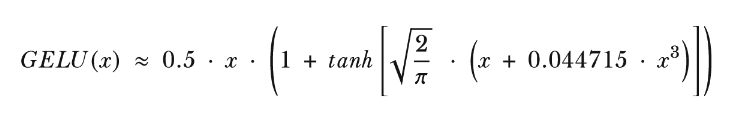

In [7]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
        ))

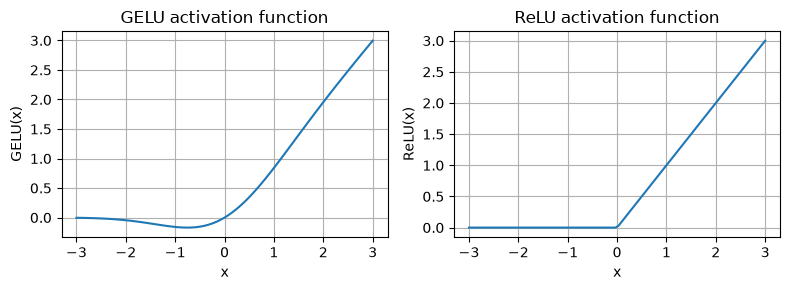

In [8]:
gelu, relu = GELU(), nn.ReLU()

x = torch.linspace(-3, 3, 100)     #1
y_gelu, y_relu = gelu(x), relu(x)
plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
# Internally expand, apply GELU and contracts later
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)

In [10]:
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.rand(2, 3, 768)          #1
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


#### Skip/ residual connections
- Introduced to mitigate the challenge of vanishing gradients where gradients becomes progressively smaller during backpropogation, making training earlier layers difficult
  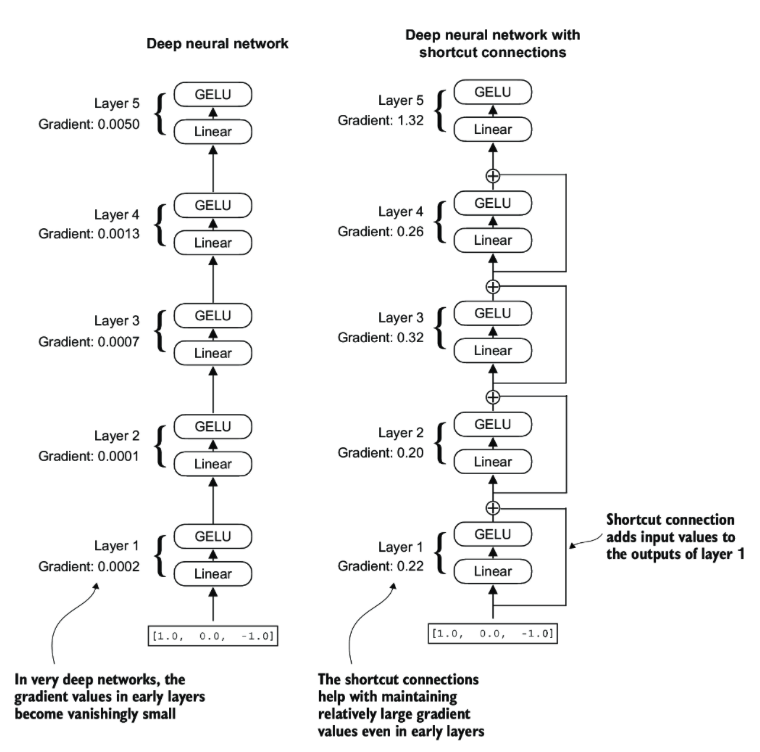

In [12]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([       #1 Defining each single linear unit followed by GELU
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), 
                          GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), 
                          GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), 
                          GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), 
                          GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), 
                          GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)         # First layer output
            if self.use_shortcut and x.shape == layer_output.shape:    #3 adding input and layer output for residula connections
                x = x + layer_output
            else:
                x = layer_output
        return x

In [14]:
# Let' see how gradients changes with and without residual connections

layer_sizes = [3, 3, 3, 3, 3, 1]  
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)                            #1
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)

def print_gradients(model, x):
    output = model(x)             #1
    target = torch.tensor([[0.]])

    loss = nn.MSELoss()
    loss = loss(output, target)    #2

    loss.backward()          #3

    for name, param in model.named_parameters():
        if 'weight' in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}") 

In [15]:
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173584925942123
layers.1.0.weight has gradient mean of 0.00012011158833047375
layers.2.0.weight has gradient mean of 0.0007152041071094573
layers.3.0.weight has gradient mean of 0.0013988735154271126
layers.4.0.weight has gradient mean of 0.005049645435065031


In [16]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)  

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694106817245483
layers.2.0.weight has gradient mean of 0.32896992564201355
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258540630340576


- The gradients of the initial layers are not shrinking to a very low value after adding the residual net connections

  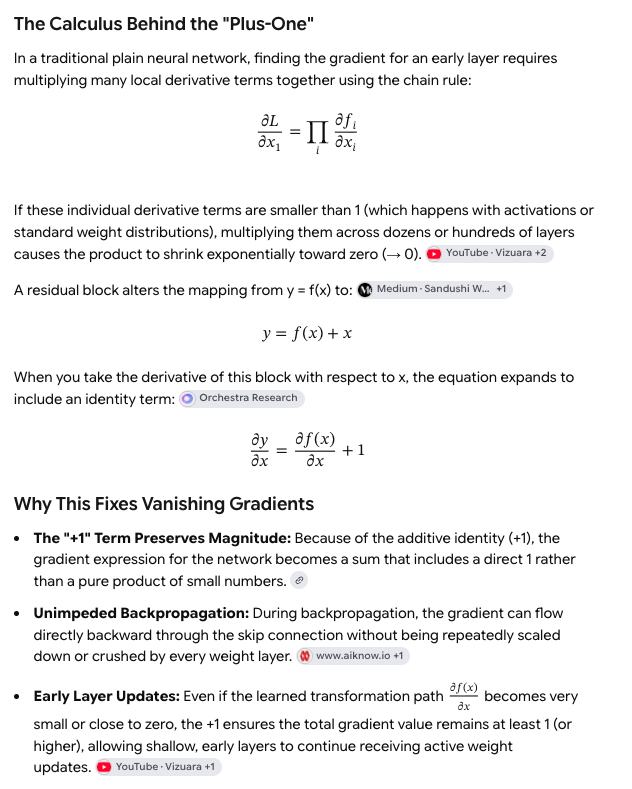

#### Transformer Block

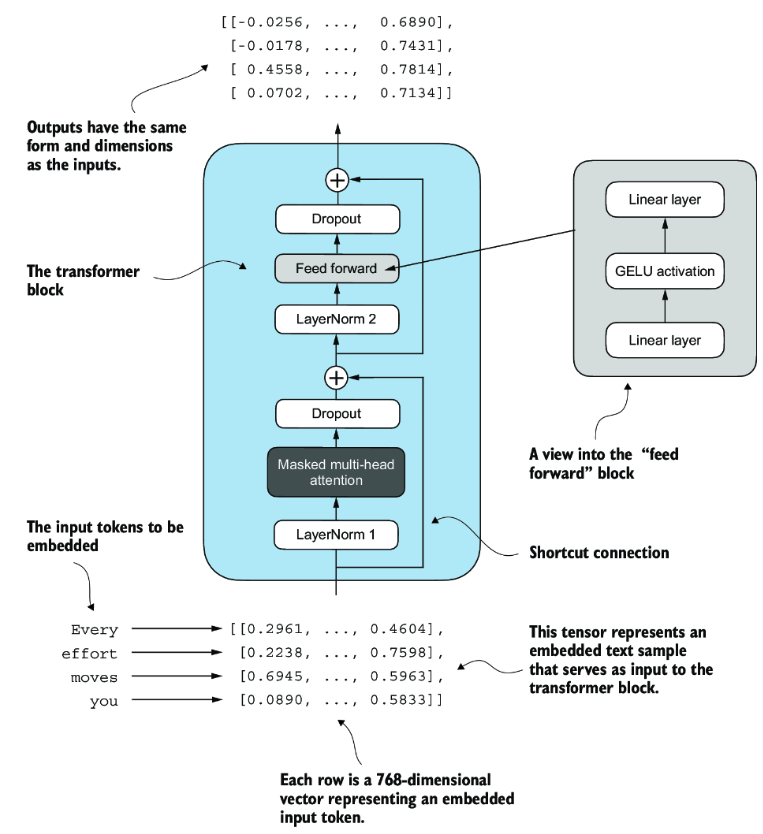

In [17]:
### Importing multi head attention from previous chapter
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, 
                 context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads    #Reduces the projection dim to match the desired output dim
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)    # Uses a Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)         #  Tensor shape: (batch, num_tokens, d_out)
        queries = self.W_query(x)    #3
        values = self.W_value(x)     #3

        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim) # dimension of each head: (batch, num_tokens, num_heads, head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)  
        queries = queries.view(                                             
            b, num_tokens, self.num_heads, self.head_dim                    
        )                                                                   

        keys = keys.transpose(1, 2)          # Transposes from shape (b, num_tokens, num_heads, head_dim) to (b, num_heads, num_tokens, head_dim)
        queries = queries.transpose(1, 2)    #5
        values = values.transpose(1, 2)      #5

        attn_scores = queries @ keys.transpose(2, 3)   # Computes dot product for each head
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]    # Using mask to fill attention scores

        attn_scores.masked_fill_(mask_bool, -torch.inf)     

        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ values).transpose(1, 2)   # Tensor shape: (b, num_tokens, n_heads, head_dim)
        context_vec = context_vec.contiguous().view(  # Combines heads, where self.d_out = self.num_heads * self.head_dim
            b, num_tokens, self.d_out
        )
        context_vec = self.out_proj(context_vec)    # Optional linear projection of contect vectors
        return context_vec 

In [20]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"], 
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x): #1
        shortcut = x
        x = self.norm1(x) # prelayer norm:  Original architecture has postlayer norm
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut      #2

        shortcut = x         #3
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut      #4
        return x # These are context embeddings encapsulating all the relations between tokens across the input sequence

In [21]:
torch.manual_seed(123)
x = torch.rand(2, 4, 768)                   #1
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


#### Now the Final GPT model
- Major difference is that the transformer block for GPT2 is repeated 12 times
- After tokenization, positional embeddings are added and also a drop out layer
- After the multiple transformer blocks, a final layer normalization and linear output layer is added
- Usually input [token, embedding] and output [token, embedding] has similiar dimensions
- In the final output layer, this is transformed into [token, vocabsize] tensor to predict the next token in the sequence. This project the transformer output into the vocabulary space of the tokenizer to generate logit for each token in the vocabulary.

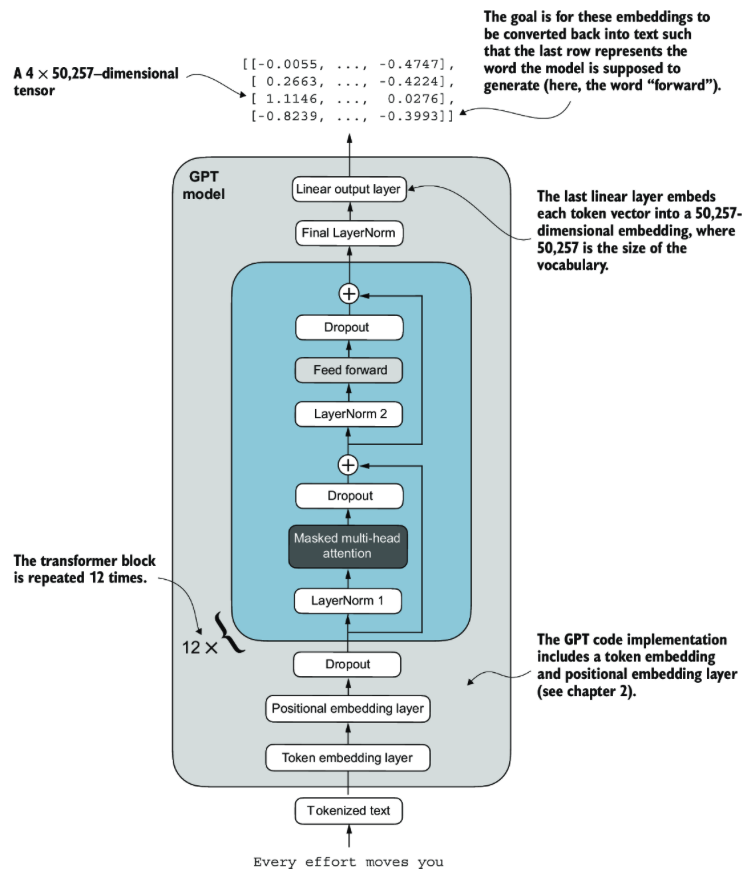

In [32]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx): # takes a batch of indices
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
 #1
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )
        #print(pos_embeds[1,:], pos_embeds[2, :])
        x = tok_embeds + pos_embeds # add token and position embeddings
        x = self.drop_emb(x) 
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [33]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

# GPT model basically takes a batch of token ids
batch = torch.tensor([[6109,  3626,  6100,   345],      #1
         [6109,  1110,  6622,   257]])
print(batch.shape)
out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

torch.Size([2, 4])
Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.3613,  0.4222, -0.0711,  ...,  0.3483,  0.4661, -0.2838],
         [-0.1792, -0.5660, -0.9485,  ...,  0.0477,  0.5181, -0.3168],
         [ 0.7120,  0.0332,  0.1085,  ...,  0.1018, -0.4327, -0.2553],
         [-1.0076,  0.3418, -0.1190,  ...,  0.7195,  0.4023,  0.0532]],

        [[-0.2564,  0.0900,  0.0335,  ...,  0.2659,  0.4454, -0.6806],
         [ 0.1230,  0.3653, -0.2074,  ...,  0.7705,  0.2710,  0.2246],
         [ 1.0558,  1.0318, -0.2800,  ...,  0.6936,  0.3205, -0.3178],
         [-0.1565,  0.3926,  0.3288,  ...,  1.2630, -0.1858,  0.0388]]],
       grad_fn=<UnsafeViewBackward0>)


In [35]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


In [36]:
total_size_bytes = total_params * 4       #1
total_size_mb = total_size_bytes / (1024 * 1024)     #2
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


#### Generating text back from the GPT model
- Model generates a token at a time. The word generate is appended to the input to generate the token. This process is continued until a coherent sentence is formed/ max size of the sentence.
- With each iteration, input context grows allowing the model to generate a coherent and contextually appropriate text

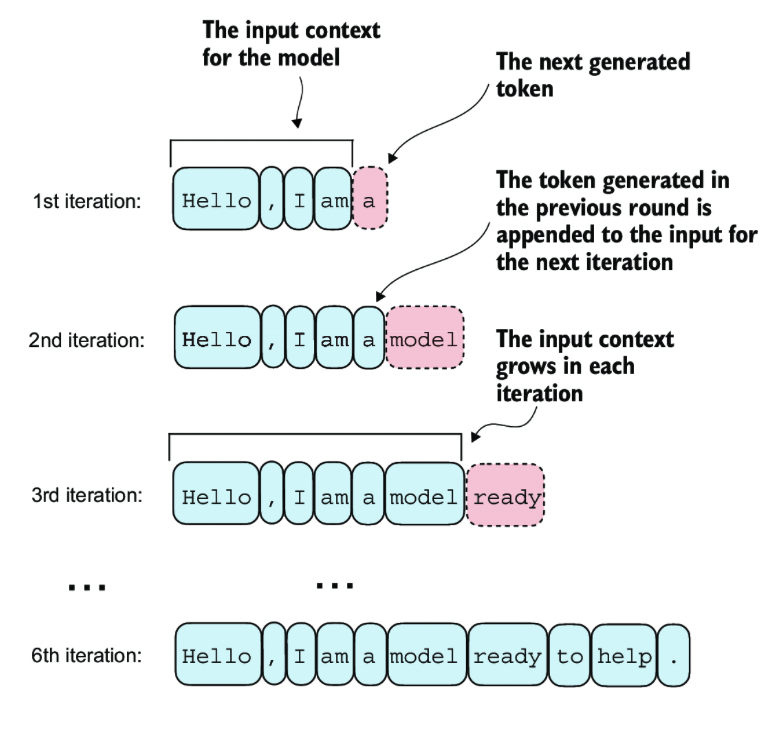

- In each step, the model outputs a matrix with vectors representing potential next tokens. The vector corresponding to the next token is extracted and converted into a probability distribution via the softmax function.
- This would generate the most likely token called greedy encoding. We can use different sampling techniques so that model does not select the most likely token introducing variability and creativity.
- Within the vector containing the resulting probability scores, the index of the highest value is located, which translates to the token ID.
-  This token ID is then decoded back into text, producing the next token in the sequence. Finally, this token is appended to the previous inputs, forming a new input sequence for the subsequent iteration.
-  This step-by-step process enables the model to generate text sequentially one token at at time, building coherent phrases and sentences from the initial input context.

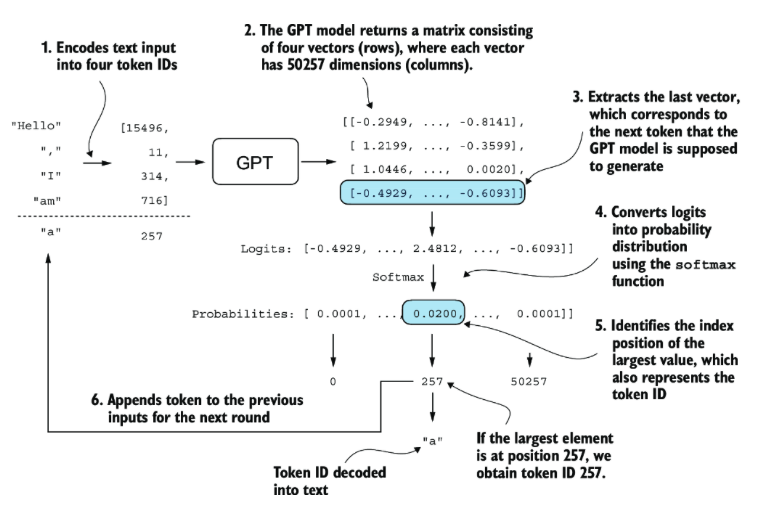

In [40]:
# A simple iterative generation loop for GPT2
def generate_text_simple(model, idx,                 #1 idx :  [batch, tokens], max_new_tokens: how many new tokens needs to be generated
                         max_new_tokens, context_size): 
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]    #2 Cropping based on the context size, selecting the last context elements
        with torch.no_grad():
            logits = model(idx_cond) # evaluate the model

        logits = logits[:, -1, :]                    #3 retrieving the logits of the last token
        probas = torch.softmax(logits, dim=-1)           #4
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)    #5 Finding the token id corresponding to the highest probs
        idx = torch.cat((idx, idx_next), dim=1)     #6 The new word is appended to the input for the next word generation

    return idx

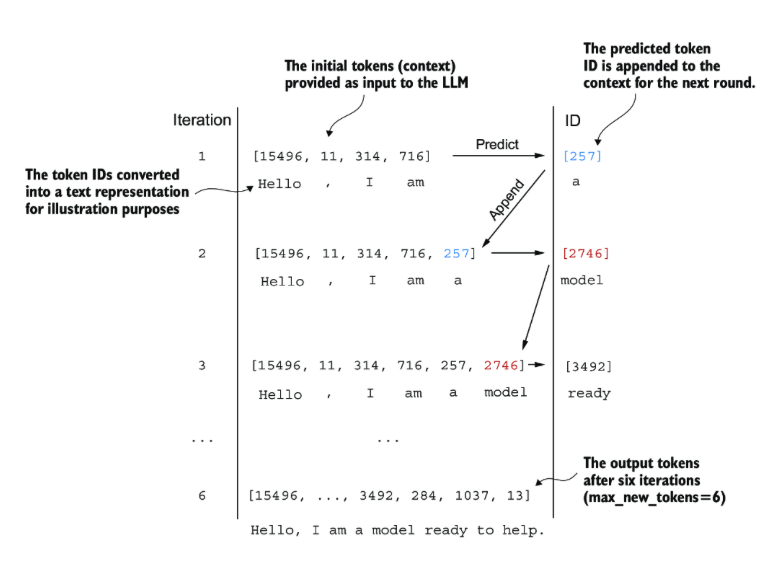

In [38]:
# Get the BPE tokenizer from GPT2
tokenizer = tiktoken.get_encoding("gpt2")

start_context = "Good morning, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0)    #1
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [10248, 3329, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 5])


In [42]:
model.eval()                  #1 Turn off all the drop out and batch normalizations
out = generate_text_simple(
    model=model,
    idx=encoded_tensor, 
    max_new_tokens=10, 
    context_size=GPT_CONFIG_124M["context_length"]
)
print("Output:", out)
print("Output length:", len(out[0]))

decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Output: tensor([[10248,  3329,    11,   314,   716, 46895,  5660,   308, 30387, 38839,
           588,  7262,  7385, 38855,  2549]])
Output length: 15
Good morning, I am pedigree Run gSpringExpress like rape KirAcceptournal
